<a href="https://colab.research.google.com/github/radita00/PCVK_Ganjil2026/blob/main/Week7_Segmentasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama	:	Radita Yoga Anugrah

Kelas 	:	3E

NIM	:	244107020099

Jobsheet Ke-	:	7


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

DIR = '/content/drive/MyDrive/PCVK/Images/'

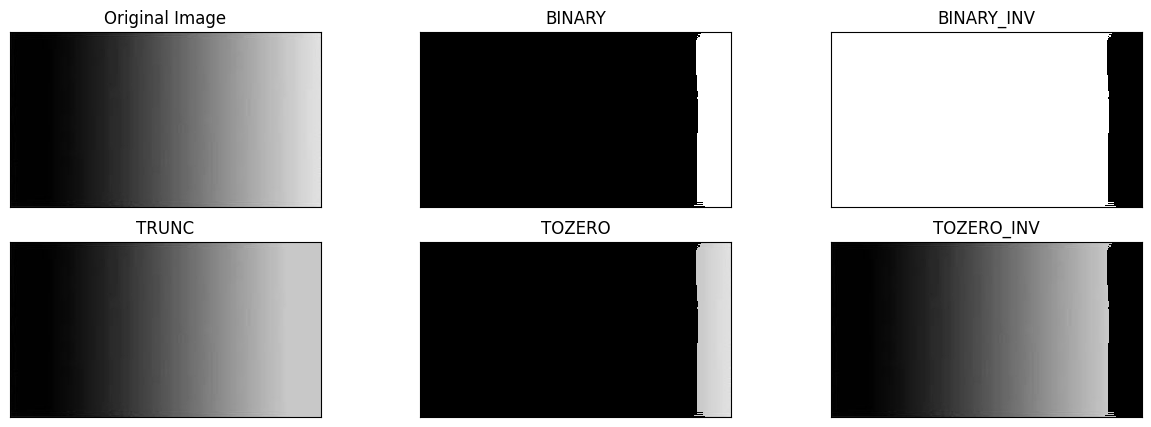

In [3]:
img = cv.imread(DIR + 'gradient.jpg', 0)
thresh = 200
maxval = 255

# 1. BINARY
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)
# 2. BINARY_INV
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)
# 3. TRUNC
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)
# 4. TOZERO
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)
# 5. TOZERO_INV
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15,5))
for i in range(len(images)):
    plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

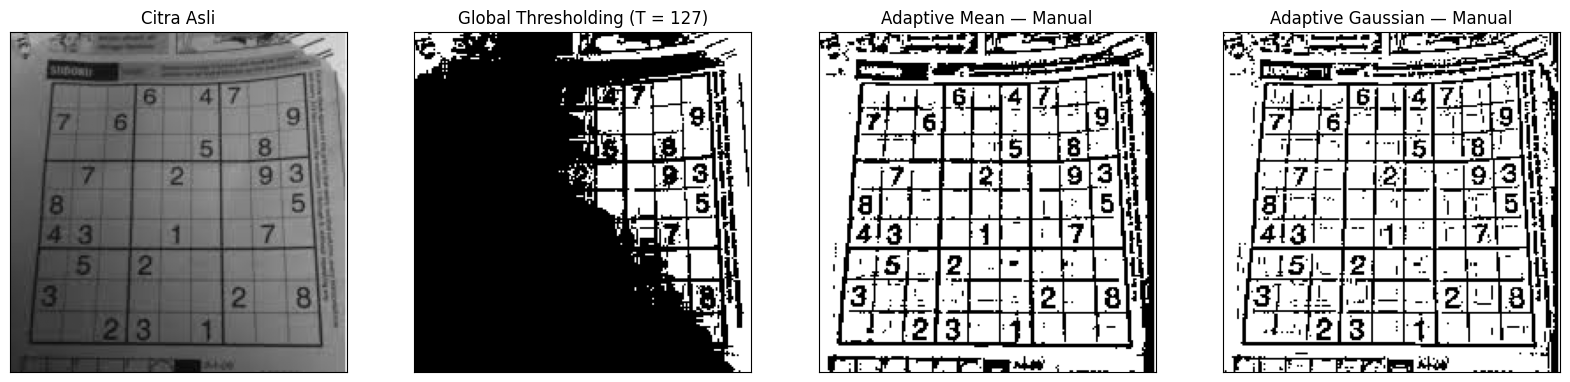

In [4]:
filename = DIR + 'sudoku-original.jpg'
gray = cv.imread(filename, 0)
H, W = gray.shape

thresh = 127
ukuran = 11
C = 2
sigma = 2
r = ukuran // 2

# Global thresholding manual
th_global = np.where(gray > thresh, 255, 0).astype(np.uint8)

# Tambah tepi (replikasi piksel pinggir) agar jendela 11x11 muat di semua piksel
pad = np.pad(gray.astype(np.float64), r, mode='edge')

# Bobot rata-rata biasa (semua sama) dan bobot Gaussian
bobot_mean = np.ones((ukuran, ukuran)) / (ukuran * ukuran)
ax = np.arange(ukuran) - r
g1d = np.exp(-(ax ** 2) / (2 * sigma ** 2))
g1d = g1d / g1d.sum()
bobot_gauss = np.outer(g1d, g1d)

# Rata-rata lokal = jumlah (bobot x piksel) pada jendela 11x11
rata_mean = np.zeros((H, W))
rata_gauss = np.zeros((H, W))
for dy in range(ukuran):
    for dx in range(ukuran):
        irisan = pad[dy:dy + H, dx:dx + W]
        rata_mean += bobot_mean[dy, dx] * irisan
        rata_gauss += bobot_gauss[dy, dx] * irisan

# T(x,y) = rata-rata - C ; bandingkan
th_mean = np.where(gray > rata_mean - C, 255, 0).astype(np.uint8)
th_gauss = np.where(gray > rata_gauss - C, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th_global, th_mean, th_gauss]
plt.figure(figsize=(20,5))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1), plt.imshow(citra2[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

/tmp/ipykernel_459/1113265043.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_459/1113265043.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


118


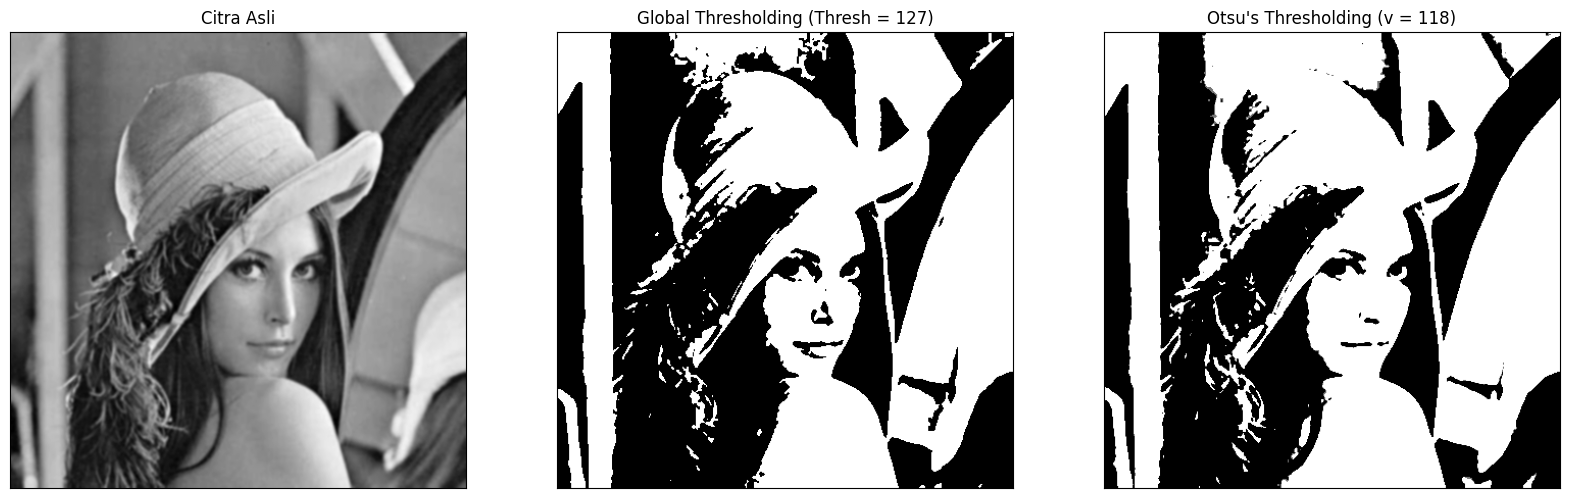

In [7]:
filename = (DIR + 'lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### Jawaban pertanyaan:

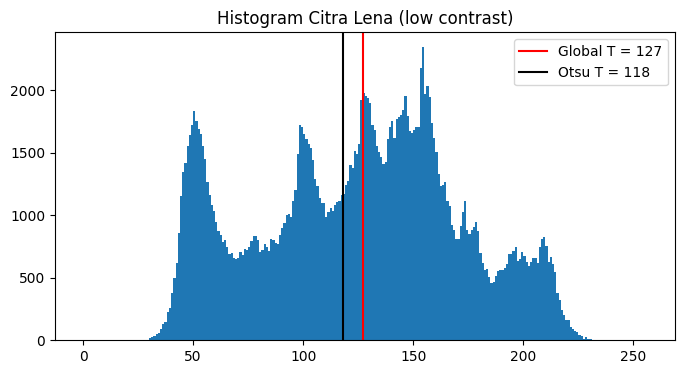

Rentang intensitas citra: 28 sampai 231


In [8]:
plt.figure(figsize=(8,4))
plt.hist(blur.ravel(), bins=256, range=(0,256))
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label="Otsu T = " + str(otsu_thresh))
plt.title('Histogram Citra Lena (low contrast)')
plt.legend()
plt.show()
print('Rentang intensitas citra:', blur.min(), 'sampai', blur.max())

**Jawaban:**
1. **Kenapa hitam semua?** Aturan Binary: piksel `> 127` jadi putih, selain itu hitam. Citra Lena ini *low contrast*: seluruh intensitasnya hanya di sekitar **85–108**, jadi **tidak ada satu piksel pun di atas 127**. Pada histogram, semua batang berada di **kiri garis merah (127)**, sehingga semuanya menjadi 0 (hitam).
2. **Ambang supaya Lena masih terlihat:** ambang harus berada di dalam rentang intensitas citra, yaitu sekitar **90–100**. Yang paling pas adalah nilai dari Otsu: **sekitar 92–93** (modul: Otsu manual 93, OpenCV 92). Garis Otsu membelah histogram jadi dua kelompok (latar dan objek), sedangkan garis 127 tidak membelah apa-apa.
3. **Kenapa manual 93 dan library 92?** Kode manual memasukkan intensitas `< t` ke latar, sedangkan OpenCV memasukkan intensitas `<= t`. Hasilnya beda 1 angka, tetapi gambarnya hampir sama.

**B.** Coba dengan KTP fulan:

/tmp/ipykernel_459/1113265043.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


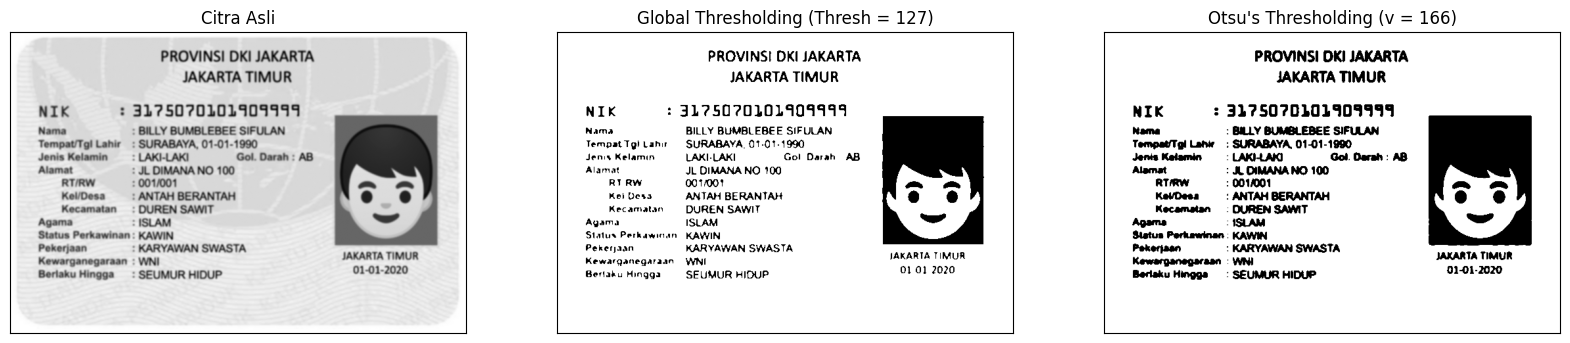

In [9]:
img_ktp = cv.imread(DIR + 'ktp_fulan.jpg', 0)
blur_ktp = cv.GaussianBlur(img_ktp,(5,5),0)

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)
ret,th1_ktp = cv.threshold(blur_ktp,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')',
          "Otsu's Thresholding (v = " + str(otsu_thresh_ktp) + ")"]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize = (20,15))
for i in range(len(citra_ktp)):
    plt.subplot(1,3,i+1),plt.imshow(citra_ktp[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

Seed Dalam koin (baris, kolom): (55, 43) | intensitas: 174.0
Seed Latar (baris, kolom): (90, 43) | intensitas: 86.0
Seed Tepi koin (baris, kolom): (55, 22) | intensitas: 170.0


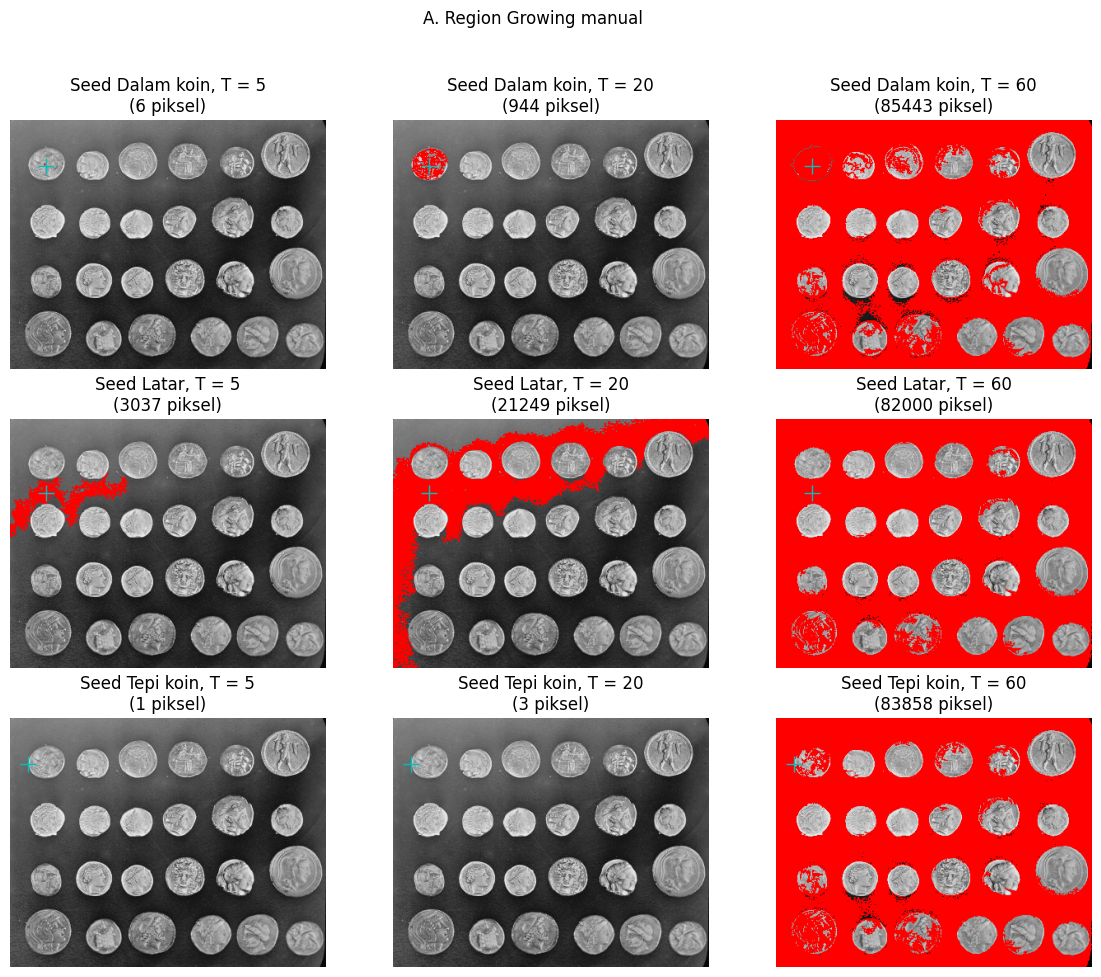

In [10]:
gray = data.coins()          # grayscale, 303 x 384

seeds = {"Dalam koin": (55, 43), "Latar": (90, 43), "Tepi koin": (55, 22)}   # (baris, kolom)
Ts = [5, 20, 60]

for nama, s in seeds.items():
    print(f"Seed {nama} (baris, kolom): {s} | intensitas: {float(gray[s])}")

def region_growing(gray, seed, T):
    tinggi, lebar = gray.shape
    mask = np.zeros((tinggi, lebar), dtype=bool)
    dikunjungi = np.zeros((tinggi, lebar), dtype=bool)
    antrean = deque([seed])
    mask[seed] = True
    dikunjungi[seed] = True
    jumlah = 1
    total = float(gray[seed])
    while antrean:
        r, c = antrean.popleft()
        for dr, dc in ((-1,0), (1,0), (0,-1), (0,1)):      # 4 tetangga
            rr, cc = r + dr, c + dc
            if 0 <= rr < tinggi and 0 <= cc < lebar and not dikunjungi[rr, cc]:
                dikunjungi[rr, cc] = True
                if abs(float(gray[rr, cc]) - total / jumlah) < T:   # |I(q) - rata-rata region| < T
                    mask[rr, cc] = True
                    total += float(gray[rr, cc])
                    jumlah += 1
                    antrean.append((rr, cc))
    return mask

def tampil_grid(fungsi_region, judul):
    plt.figure(figsize=(14,11))
    plt.suptitle(judul)
    i = 1
    for nama, s in seeds.items():
        for T in Ts:
            mask = fungsi_region(gray, s, T)
            rgb = np.stack([gray, gray, gray], axis=-1)
            rgb[mask] = [255, 0, 0]
            plt.subplot(3, 3, i)
            plt.imshow(rgb)
            plt.plot(s[1], s[0], 'c+', markersize=12)
            plt.title(f"Seed {nama}, T = {T}\n({mask.sum()} piksel)")
            plt.axis('off')
            i += 1
    plt.show()

tampil_grid(region_growing, "A. Region Growing manual")

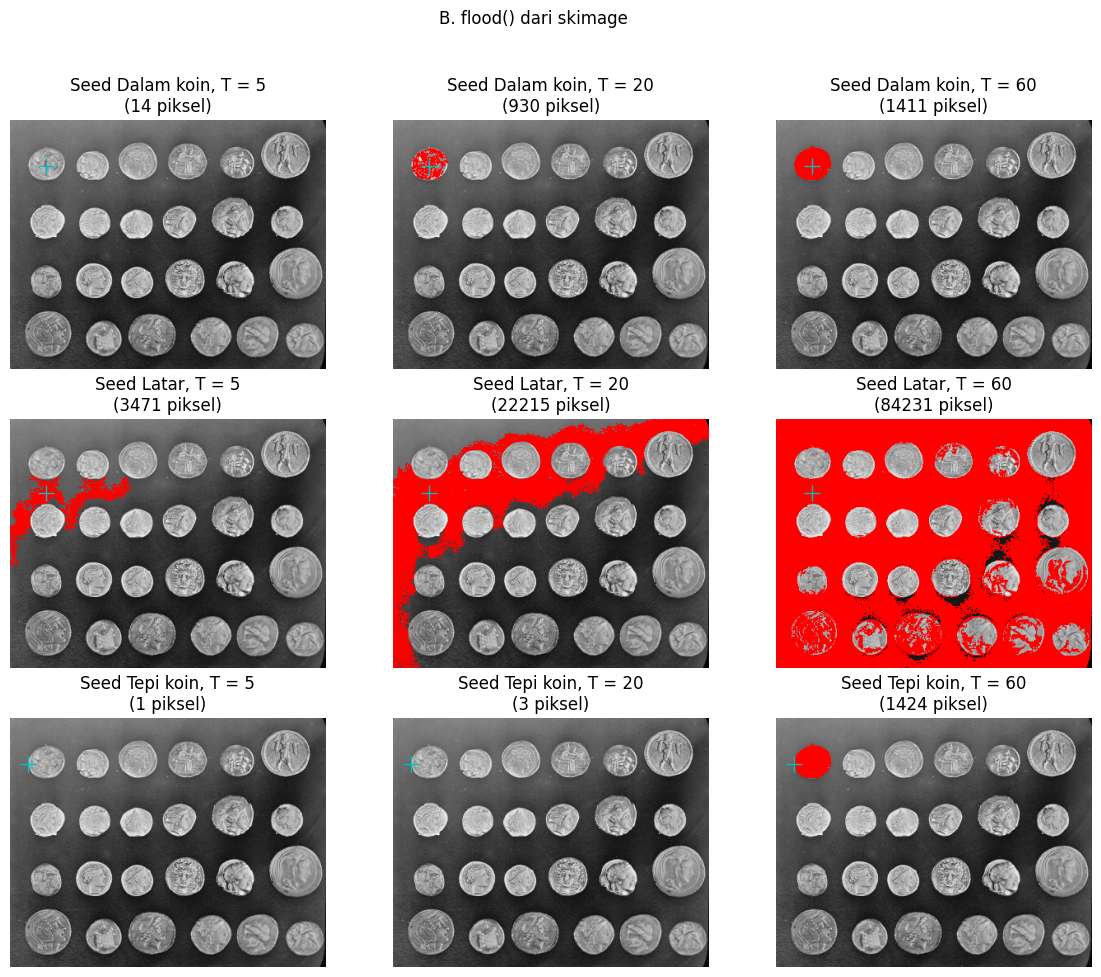

In [11]:
def region_flood(gray, seed, T):
    return flood(gray, seed_point=seed, tolerance=T, connectivity=1)   # 4 tetangga untuk citra 2D

tampil_grid(region_flood, "B. flood() dari skimage")

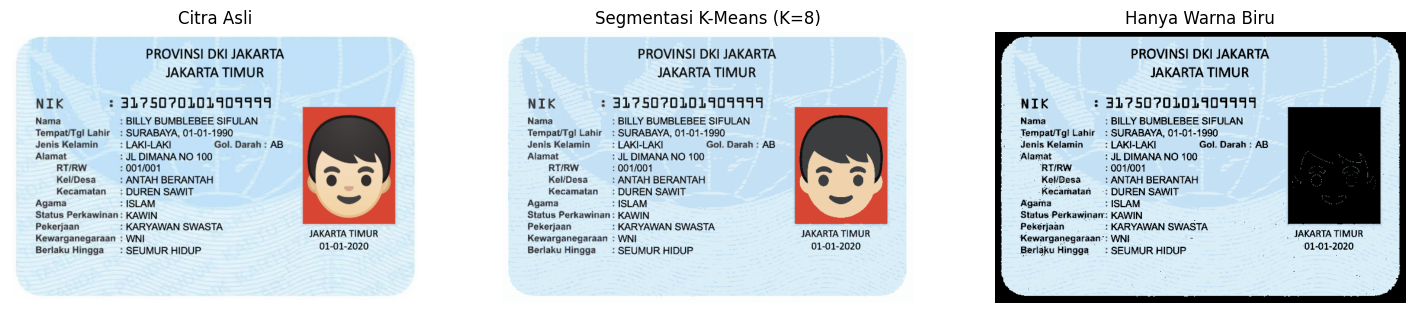

In [12]:
from sklearn.cluster import KMeans

img = cv.imread(DIR + 'ktp_fulan.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# K-Means dengan K = 8
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Ambil hanya warna biru (HSV)
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = cv.split(hsv)
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]

plt.figure(figsize=(18,5))
plt.subplot(1,3,1); plt.imshow(img); plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(segmented_img); plt.title('Segmentasi K-Means (K=8)'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(hanya_biru); plt.title('Hanya Warna Biru'); plt.axis('off')
plt.show()

# Tugas Kelompok:

In [13]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


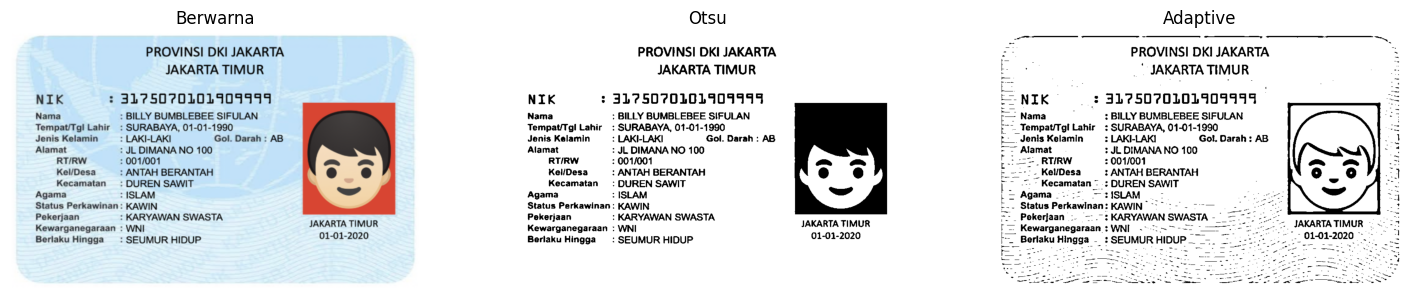

In [14]:
import pytesseract
from pytesseract import Output
import difflib

img_warna = cv.imread(DIR + 'ktp_fulan.jpg')
img_warna = cv.resize(img_warna, (1000, 630))               # ukuran sama untuk ketiganya
gray = cv.cvtColor(img_warna, cv.COLOR_BGR2GRAY)

_, img_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)

citra = {"Berwarna": img_warna, "Otsu": img_otsu, "Adaptive": img_adaptive}

plt.figure(figsize=(18,6))
for i, (nama, im_) in enumerate(citra.items()):
    plt.subplot(1,3,i+1)
    if im_.ndim == 3:
        plt.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB))
    else:
        plt.imshow(im_, 'gray')
    plt.title(nama); plt.axis('off')
plt.show()

In [15]:
LANG = 'ind'
CONFIG = '--psm 6'

for nama, im_ in citra.items():
    print("==========", nama.upper(), "==========")
    print(pytesseract.image_to_string(im_, lang=LANG, config=CONFIG))

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1: 31?50?0101404114
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3)?5D70101901917
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat 1 JL DIMANA NO 100

RT/RW : 001/001

KeliDesa 1 ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan ! KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========== ADAPTIVE ==========
MD OA (Tw oo
Fa PROVINSI DKI JAKARTA z
pa . “JAKARTA TIMUR Fa
Ic : E
&- NIK ..3 

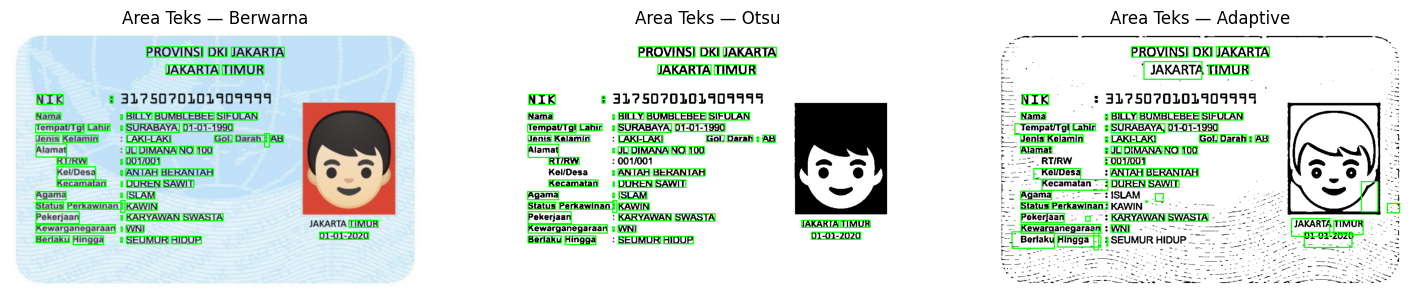

In [16]:
BATAS = 60
hasil_data = {}

plt.figure(figsize=(18,6))
for i, (nama, im_) in enumerate(citra.items()):
    d = pytesseract.image_to_data(im_, lang=LANG, config=CONFIG, output_type=Output.DICT)
    hasil_data[nama] = d
    tampil = im_.copy() if im_.ndim == 3 else cv.cvtColor(im_, cv.COLOR_GRAY2BGR)
    for j in range(len(d['text'])):
        if d['text'][j].strip() != '' and float(d['conf'][j]) > BATAS:
            x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
            cv.rectangle(tampil, (x, y), (x + w, y + h), (0, 255, 0), 2)
    plt.subplot(1,3,i+1)
    plt.imshow(cv.cvtColor(tampil, cv.COLOR_BGR2RGB))
    plt.title("Area Teks — " + nama); plt.axis('off')
plt.show()

In [17]:
acuan = ["PROVINSI", "JAKARTA", "TIMUR", "NIK", "Nama", "Alamat", "Agama", "ISLAM", "KAWIN", "SEUMUR"]   # GANTI sesuai KTP

def kata_ocr(d):
    return [t.strip().lower() for t in d['text'] if t.strip() != '']

def paling_mirip(item, kata):
    m = difflib.get_close_matches(item.lower(), kata, n=1, cutoff=0.0)
    return m[0] if m else "(tidak terbaca)"

tabel = pd.DataFrame({"No": range(1, len(acuan) + 1), "Teks sebenarnya": acuan})
ringkasan = []
for nama in citra:
    d = hasil_data[nama]
    kata = kata_ocr(d)
    hasil = [paling_mirip(a, kata) for a in acuan]
    tabel["OCR " + nama] = hasil
    tepat = sum(h == a.lower().strip() for h, a in zip(hasil, acuan))
    conf = [float(c) for t, c in zip(d['text'], d['conf']) if t.strip() != '' and float(c) >= 0]
    ringkasan.append({"Citra masukan OCR": nama, "Item terbaca tepat": tepat,
                      "Kecocokan (%)": tepat / len(acuan) * 100,
                      "Rata-rata confidence": round(float(np.mean(conf)), 1) if conf else 0})

display(tabel)
display(pd.DataFrame(ringkasan))

,No,Teks sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,provinsi,provinsi,provinsi
1,2,JAKARTA,jakarta,jakarta,jakarta
2,3,TIMUR,timur,timur,timur
3,4,NIK,nik,nik,nik
4,5,Nama,nama,nama,nama
5,6,Alamat,alamat,alamat,alamat
6,7,Agama,agama,agama,agama
7,8,ISLAM,islam,islam,—3islam
8,9,KAWIN,kawin,kawin,kawin.
9,10,SEUMUR,seumur,seumur,seumur


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna,10,100.0,87.4
1,Otsu,10,100.0,83.8
2,Adaptive,8,80.0,46.4


### Pertanyaan analisis
Jawaban 1 dan 2 harus diisi dari **tabel hasil jalan di KTP kelompok Anda** (angkanya berbeda tiap KTP). Jawaban 3–5 adalah penjelasan umum yang biasanya terbukti dari hasil percobaan; cocokkan dengan tabel Anda.

1. **Citra masukan mana yang paling tepat?** Citra berwarna dengan kecocokan 100% dan rata rata confidence 87.4
2. **Dua kesalahan pembacaan.** —3islam dan kawin.
3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?** Tidak selalu. Thresholding membuang warna dan hanya menyisakan hitam-putih. Jika ambang cocok, tulisan menjadi jelas dan latar hilang. Jika ambang tidak cocok, huruf tipis ikut hilang atau latar berbintik sehingga OCR salah baca. Pada citra berwarna, Tesseract memakai pengolahan bawaannya sendiri sehingga kadang sudah cukup baik.
4. **Pengaruh warna/pola latar.** Latar yang gelap, bergambar, atau berpola (seperti guratan biru muda pada KTP) mengurangi kontras antara huruf dan latar, sehingga huruf kecil mudah dianggap bagian pola. Latar polos dan kontras tinggi (hitam di atas putih) paling mudah dibaca. Otsu memakai satu ambang untuk seluruh citra sehingga pola latar yang tidak merata bisa tetap tersisa; Adaptive lebih tahan pada pencahayaan tidak merata tetapi dapat menimbulkan bintik pada area polos.
5. **Apakah confidence tertinggi = kecocokan tertinggi?** Belum tentu. Confidence hanyalah keyakinan Tesseract terhadap pembacaannya sendiri dan hanya dihitung pada kata yang terdeteksi. Metode yang hanya mendeteksi sedikit kata jelas bisa punya confidence tinggi tetapi kecocokannya rendah, karena banyak item tidak terbaca.